In [45]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import scipy.sparse as sps
import jlinops




# from solvers import GKSIAS
# from psolvers import PGKSIAS
# from rsolvers import RIASGKS

from msolver import MMGKS

# Setup toy problem

In [2]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.1
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=10, mode="reflect") # was 10
#A = jlinops.IdentityOperator((n,n))
b = A.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

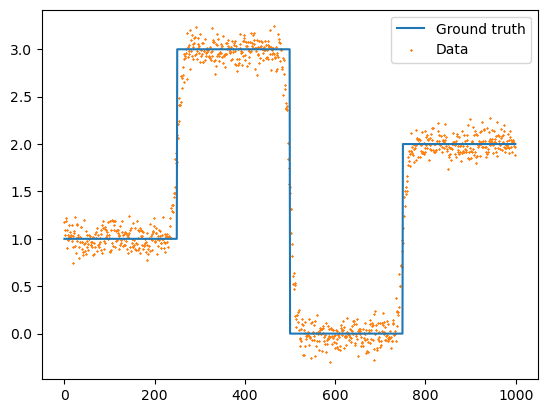

In [3]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, b, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization

In [4]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

# Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="zero")
# L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

# Set parameters

In [13]:
n_iters = 200
q = 0.5
epsilon = 1e-5
weight_params = {
    "q": q,
    "epsilon": epsilon,
}

In [14]:
# Set method
method = "dp3"

# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

K = jlinops.MatrixLinearOperator(Kmat)


err_norm_sq = len(b) # in expectation

# Build solver
mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)


# # Run the solver
# ias_data = ias_solver.solve(n_iter=n_iters, init_dim=5, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=method, regparam_fixed=1e0)


In [39]:
data = mmgks_solver.solve(n_iter=100, init_dim=5, x0=None, lambdah0=None, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

pdata = mmgks_solver.solve_with_priorconditioning(n_iter=40, init_dim=5, x0=None, lambdah0=1e-3, lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

0.0015228211560391468
2.496460973402579e-05
5.138653787148372e-06
3.7163474650225036e-06
3.882069446901818e-06
2.9847763186434067e-06
2.484258506914493e-06
2.4886966280733027e-06
8.752516859096167e-06
0.0001433377320475464
0.00017832070828338676
0.00021032101045586002
0.0002639977632342378
0.00023152596453942799
0.00023702514930803986
0.00019211398262659557
0.00011462025304140909
3.1649005935653283e-06
9.109763462173415e-07
1.028129404908855e-06
2.212099261663396e-06
1.489498953787461e-06
9.432864872450204e-07
7.986446182354545e-07
7.547228059472371e-07
6.476909400603875e-07
6.073604824651087e-07
1.1235618213969641e-06
1.7567388519010324e-06
8.804131792813571e-05
0.00010232117795948771
0.00010845516071693392
6.025352528557421e-05
5.570773857740668e-06
1.3882993770791376e-05
9.284451299840571e-06
1.6663312539183752e-05
3.0187664112202002e-06
2.4460142667794075e-05
10000000.0
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an

73161.59148706154
2.886422778895188
7.679176274993259
18.079016602022218
43.129639508894144
95.78918794264173
221.82287337131078
552.5272310472011
1300.1782553683506
1675.0510583307107
1696.562338610956
1696.6285472665465
1696.6284025989241
1696.628384005537
1696.6283828931792
1696.6283828305006
1696.6283828270025
1696.6283828268076
1696.6283828268135
1696.6283828268179
1696.628382826796
1696.6283828268186
1696.6283828268654
1696.6283828268
1696.6283828268542
1696.628382826769
1696.6283828268288
1696.6283828268497
1696.6283828268304
1696.6283828268417
1696.6283828267942
1696.628382826802
1696.6283828268045
1696.6283828267926
1696.628382826832
1696.6283828267945
1696.628382826867
1696.6283828267622
1696.6283828267747
1696.628382826864


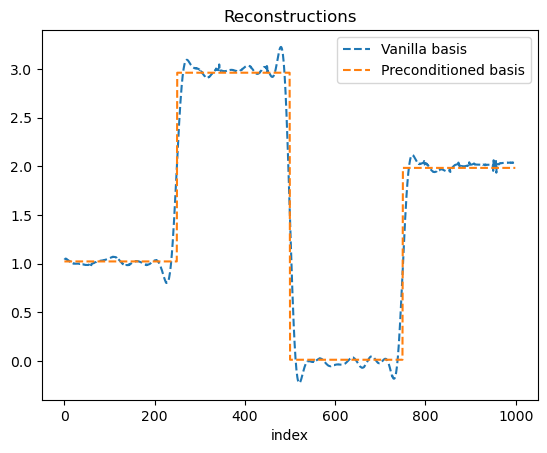

In [40]:
plt.plot(data['x'], label="Vanilla basis", ls="--")
plt.plot(pdata['x'], label="Preconditioned basis", ls="--")
# plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.4)
plt.title("Reconstructions")
plt.xlabel("index")
plt.legend()
plt.show()

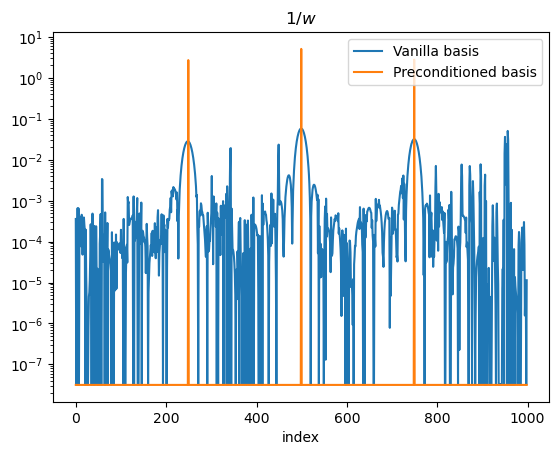

In [41]:
plt.semilogy(1.0/data['w'], label="Vanilla basis")
plt.semilogy(1.0/pdata['w'], label="Preconditioned basis")
plt.title("$1/w$")
plt.xlabel("index")
plt.legend()
plt.show()

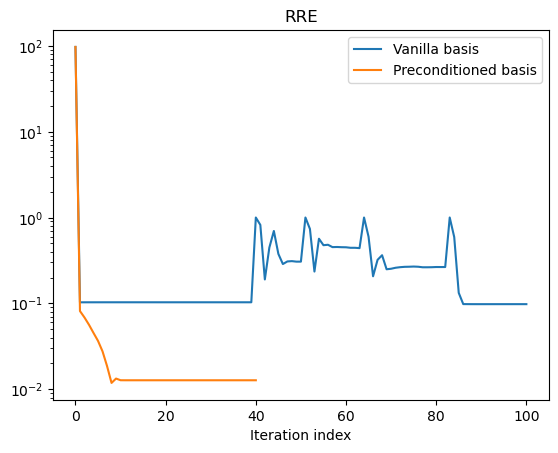

In [42]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

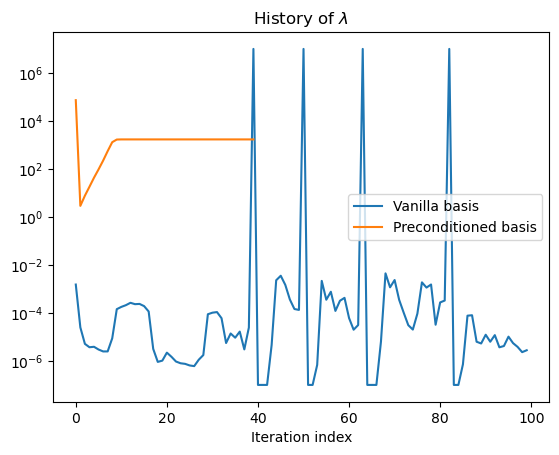

In [43]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

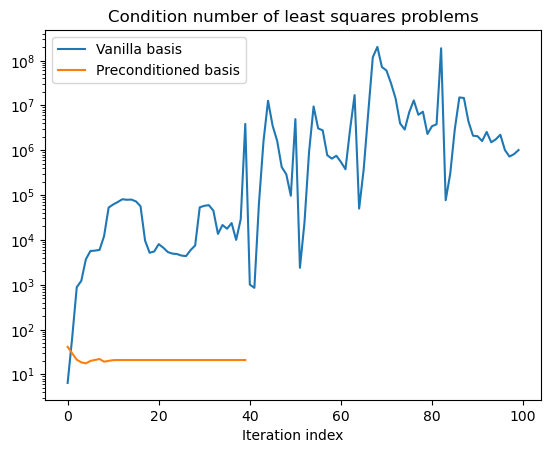

In [44]:
plt.semilogy(data["cond_ests"], label="Vanilla basis")
plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

In [7]:
from msolver import VanillaGKS

In [8]:
vgks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
vdata = vgks_solver.solve(n_iter=200, init_dim=5, x0=None, lambdah0=None,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

821.0551089993296
821.4151998201779
821.3901060354677
821.4053581593607
821.4777572599781
821.6313916306456
821.7189358756699
821.7486613995537
821.7565766042517
821.7572207683622
821.7535585197996
821.7443547056434
821.7320904354671
821.7228450527259
821.717664000043
821.7153405054983
821.7144428807262
821.7141845925955
821.7144293477577
821.7150821213198
821.7158755511535
821.7167237950634
821.7174845442937
821.7182602863012
821.7190092327257
821.7197457505068
821.720388112569
821.7208547053443
821.7211832398755
821.7214085001766
821.7215538731358
821.7216238130179
821.7216422931311
821.721628533791
821.7215900564701
821.7215382125953
821.721488357616
821.721442406354
821.7214012582743
821.7213577300699
821.7213211262161
821.7212853685652
821.7212590775292
821.7212298850769
821.7212135678582
821.7212047258218
821.7211984647465
821.7211939454004
821.7211901492739
821.7211870216323
821.7211844786189
821.7211825942484
821.7211812070135
821.7211799365161
821.7211786433384
821.72117743099

In [10]:
vdata["x"]

array([ 1.10404444e+00,  1.10310186e+00,  1.10123933e+00,  1.09850119e+00,
        1.09495165e+00,  1.09067315e+00,  1.08576321e+00,  1.08033147e+00,
        1.07449559e+00,  1.06837840e+00,  1.06210348e+00,  1.05579141e+00,
        1.04955607e+00,  1.04350147e+00,  1.03771870e+00,  1.03228367e+00,
        1.02725528e+00,  1.02267502e+00,  1.01856569e+00,  1.01493244e+00,
        1.01176337e+00,  1.00903079e+00,  1.00669397e+00,  1.00470151e+00,
        1.00299407e+00,  1.00150728e+00,  1.00017472e+00,  9.98931204e-01,
        9.97715079e-01,  9.96471208e-01,  9.95152659e-01,  9.93721967e-01,
        9.92152474e-01,  9.90428367e-01,  9.88545040e-01,  9.86508011e-01,
        9.84331738e-01,  9.82038641e-01,  9.79656888e-01,  9.77218324e-01,
        9.74756655e-01,  9.72306071e-01,  9.69898931e-01,  9.67564515e-01,
        9.65328499e-01,  9.63211634e-01,  9.61229456e-01,  9.59392241e-01,
        9.57706154e-01,  9.56173508e-01,  9.54793415e-01,  9.53563324e-01,
        9.52479598e-01,  

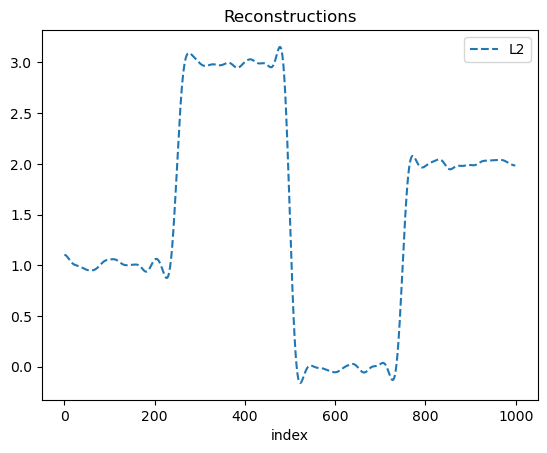

In [12]:
plt.plot(vdata['x'], label="L2", ls="--")
# plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.4)
plt.title("Reconstructions")
plt.xlabel("index")
plt.legend()
plt.show()

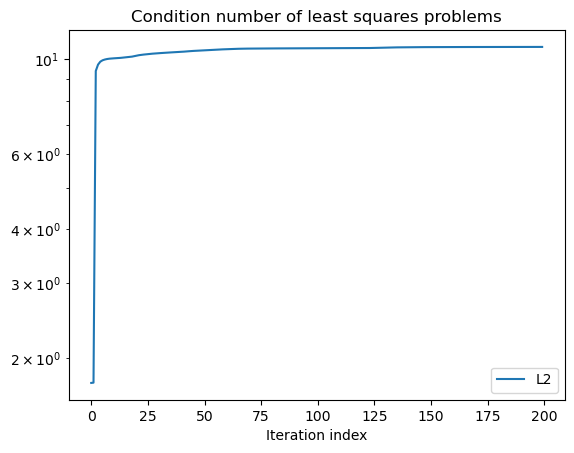

In [13]:
plt.semilogy(vdata["cond_ests"], label="L2")
#plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

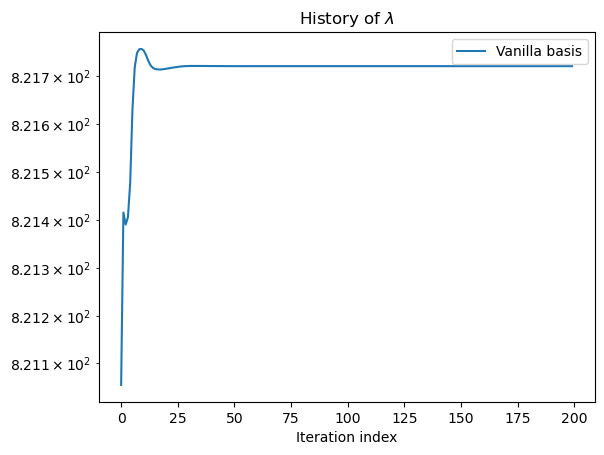

In [15]:
plt.semilogy(vdata["lambda_history"], label="Vanilla basis")
#plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# IAS solve

In [6]:
# Set method
method = "dp2"

# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

W = jlinops.MatrixLinearOperator(Wmat)


Atilde = (1.0/noise_stdev)*A
btilde = (1.0/noise_stdev)*b

err_norm_sq = len(b) # in expectation

# Build solver
ias_solver = GKSIAS(A, L, b, noise_var=noise_var)

# Run the solver
ias_data = ias_solver.solve(n_iter=n_iters, init_dim=5, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=method, regparam_fixed=1e0)


# 

In [7]:
# Set method
method = "dp2"


# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

W = jlinops.MatrixLinearOperator(Wmat)


Atilde = (1.0/noise_stdev)*A
btilde = (1.0/noise_stdev)*b

err_norm_sq = len(b) # in expectation

pias_data = PGKSIAS(Atilde, btilde, L, W=W, Lpinv_factory=Lpinv_factory, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, 
                           projection_dim=8, n_iter=n_iters, regparam=method, x_true=ground_truth, x0=None, shift_scale=1.0, regparam_fixed=1e0,
                           err_norm_sq=err_norm_sq)

running MMGKS...: 100%|██████████| 200/200 [02:12<00:00,  1.51it/s]


# RIAS

In [8]:
n_iters = 1000

kmin = 15
kmax = 30

# Set method
method = "dp2"

# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

W = jlinops.MatrixLinearOperator(Wmat)


Atilde = (1.0/noise_stdev)*A
btilde = (1.0/noise_stdev)*b

err_norm_sq = len(b) # in expectation

rias_solver = RIASGKS(A, L, b, noise_var=noise_var)

rias_data = rias_solver.solve(n_iter=n_iters, kmin=kmin, kmax=kmax, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=method, regparam_fixed=1e0)

# Comparison

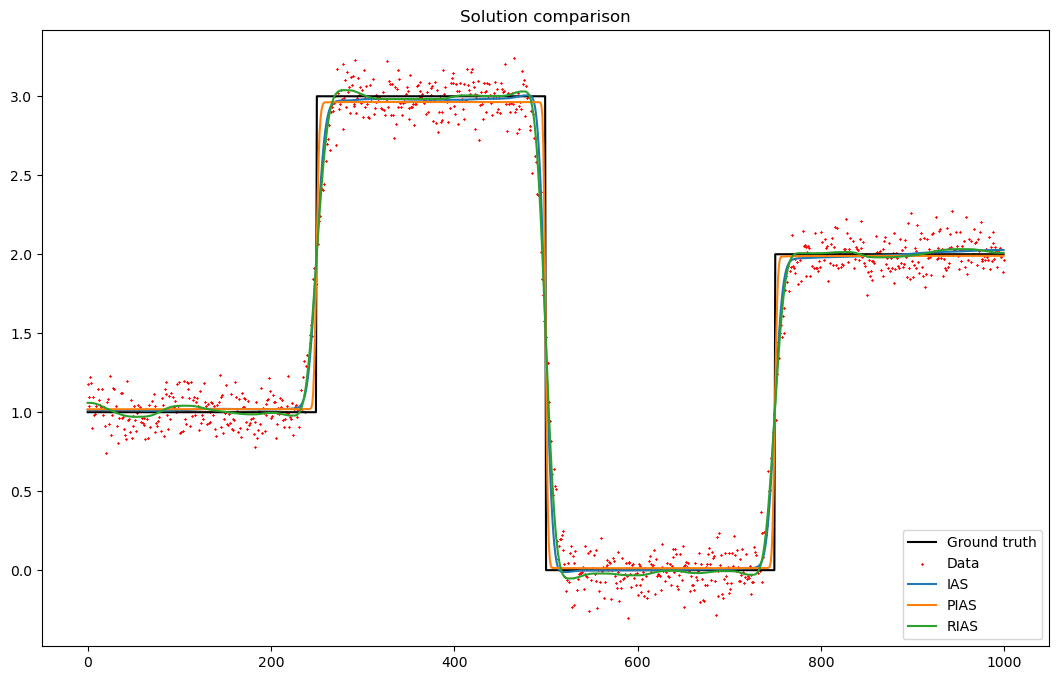

In [9]:
plt.figure(figsize=(13,8))

plt.plot(grid, ground_truth, label="Ground truth", color="black")
plt.scatter(grid, b, marker="x", label="Data", color="red", alpha=1.0, s=0.5)


plt.plot(grid, ias_data["x"], label="IAS")
plt.plot(grid, pias_data[0], label="PIAS")
plt.plot(grid, rias_data["x"], label="RIAS")


plt.legend(loc="lower right")
plt.title("Solution comparison")
plt.show()

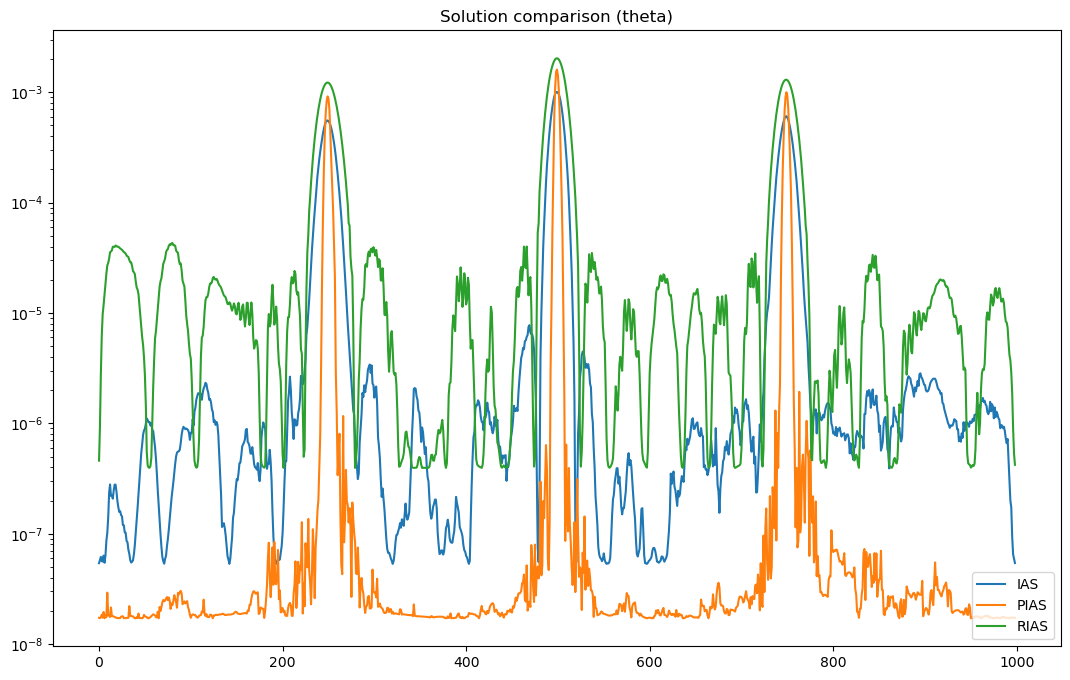

In [10]:
plt.figure(figsize=(13,8))

plt.semilogy(grid[:-1], ias_data["theta"], label="IAS")
plt.semilogy(grid[:-1], pias_data[1]["theta"], label="PIAS")
plt.semilogy(grid[:-1], rias_data["theta"], label="RIAS")

plt.legend(loc="lower right")
plt.title("Solution comparison (theta)")
plt.show()

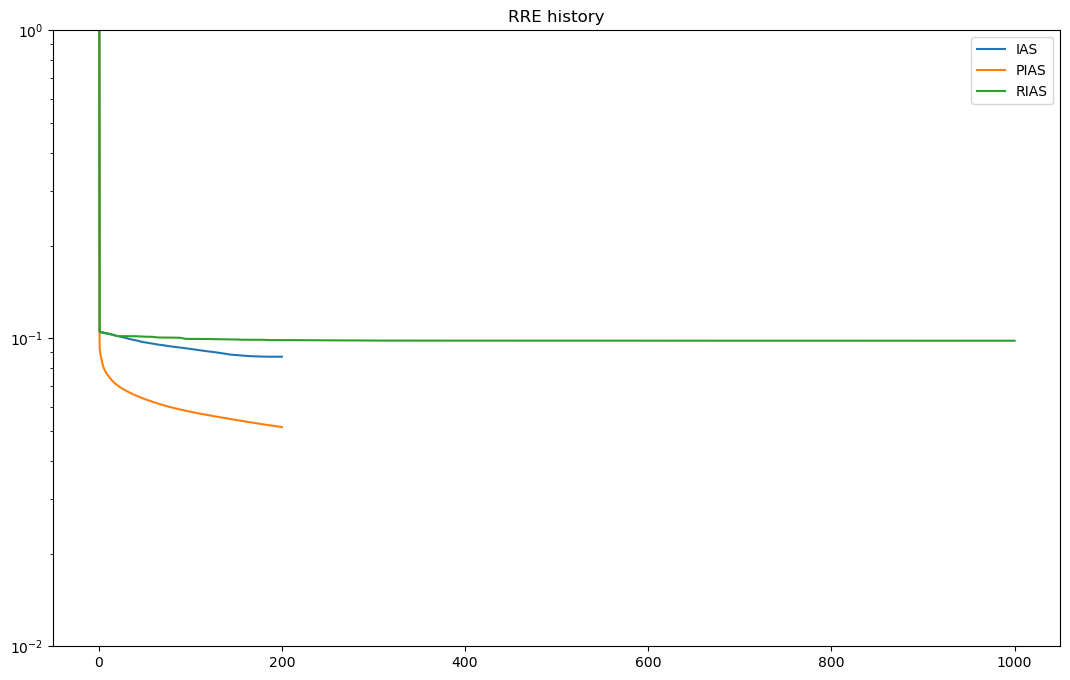

In [11]:
plt.figure(figsize=(13,8))

plt.semilogy(ias_data["rre_history"], label="IAS")
plt.semilogy(pias_data[1]["relError"], label="PIAS")
plt.semilogy(rias_data["rre_history"], label="RIAS")

plt.legend(loc="upper right")
plt.title("RRE history")
plt.ylim(1e-2, 1e-0)
plt.show()

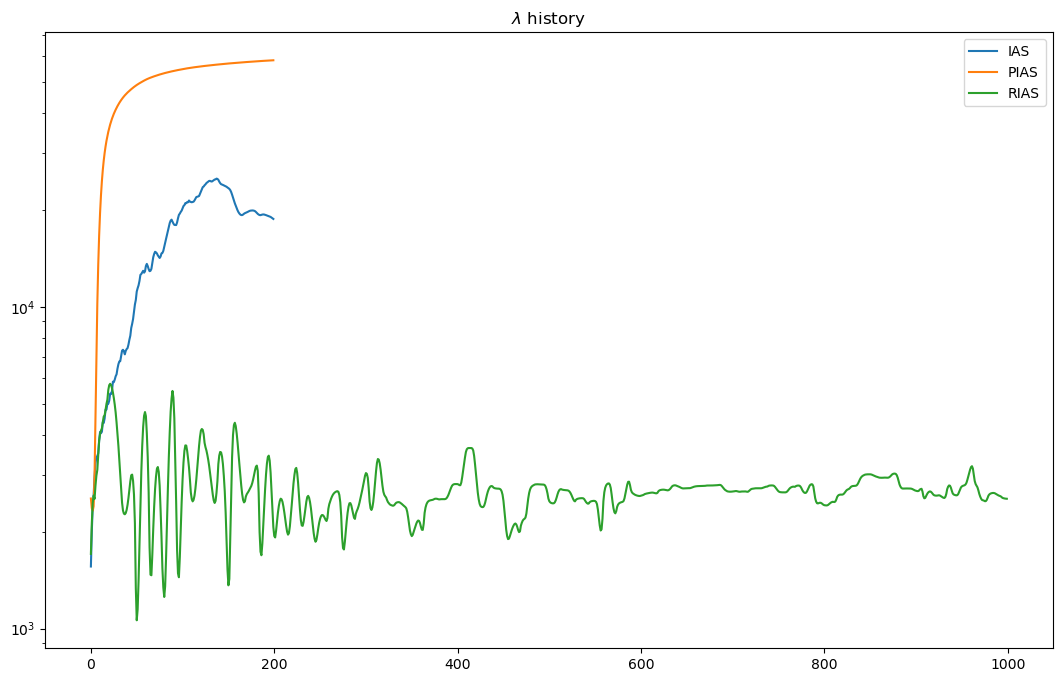

In [12]:
plt.figure(figsize=(13,8))

plt.semilogy(ias_data["lambda_history"], label="IAS")
plt.semilogy(pias_data[1]["regParam_history"], label="PIAS")
plt.semilogy(rias_data["lambda_history"], label="RIAS")

plt.legend(loc="upper right")
plt.title("$\\lambda$ history")
plt.show()

# First couple basis vectors?

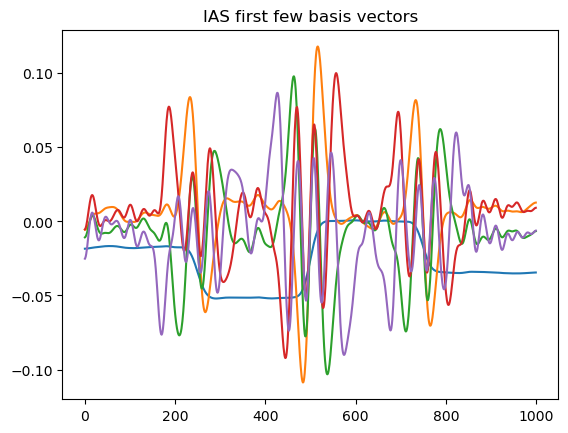

In [17]:
for j in range(5):
    plt.plot(ias_data["V"][:,j] )
plt.title("IAS first few basis vectors")
plt.show()

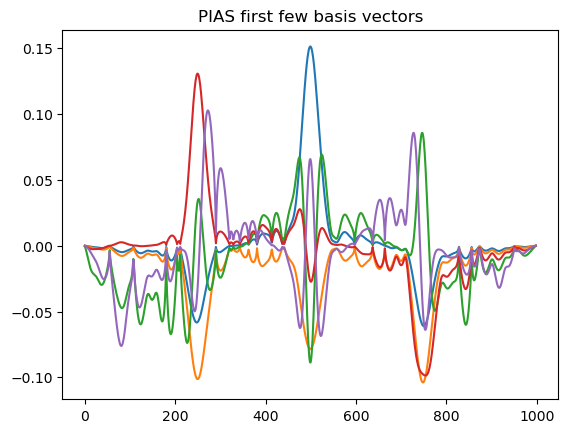

In [18]:
for j in range(5):
    plt.plot(pias_data[1]["V"][:,j] )
plt.title("PIAS first few basis vectors")
plt.show()

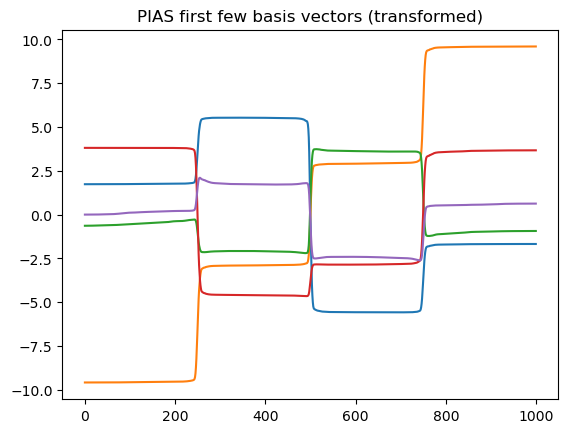

In [19]:
for j in range(5):
    plt.plot(pias_data[1]["LopinvV"][:,j] )
plt.title("PIAS first few basis vectors (transformed)")
plt.show()

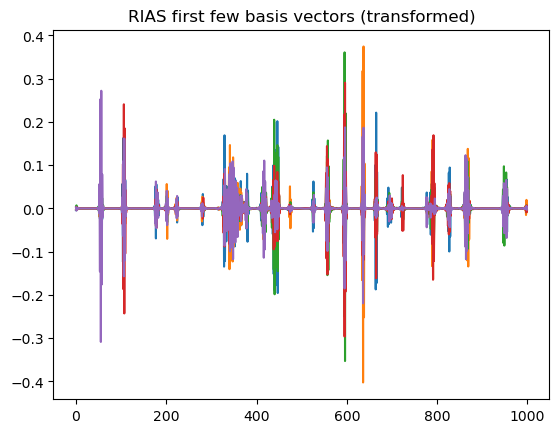

In [20]:
for j in range(5):
    plt.plot( rias_data["V"][:,j] )
plt.title("RIAS first few basis vectors (transformed)")
plt.show()